# 04 — Forecasting to 2035

Notebook 03 established two drivers of caffeine intake: age (rises through
midlife, peaks around 45-50, then falls) and birth cohort (each later cohort
roughly 3.25 mg/day lower at the same age).

This notebook turns that into a forecast:

1. Fit a weighted linear baseline and a gradient boosting challenger
2. Validate on held-out **future** cycles, not a random split
3. Project the winner to 2035
4. Repeat for the share above the FDA 400 mg limit

The validation design matters. A random train/test split would let the model
see 2021 data while predicting 2017, which inflates the score and says nothing
about whether it extrapolates. Training on everything through 2015-16 and
testing on 2017-18 and 2021-23 tests the thing we actually need.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

CLEAN = Path("../data/clean")
GEN_ORDER = ["Silent", "Boomer", "Gen X", "Millennial", "Gen Z"]

df = pd.read_csv(CLEAN / "pooled_adults.csv").query("generation != 'Other'")

FEATURES = ["age", "birth_year"]
TARGET = "caffeine_mg"

print(f"{len(df):,} records | cycles {df.cycle.nunique()} | "
      f"ages {df.age.min():.0f}-{df.age.max():.0f} | "
      f"births {df.birth_year.min():.0f}-{df.birth_year.max():.0f}")

54,837 records | cycles 11 | ages 18-80 | births 1928-2003


In [2]:
TRAIN_MAX = 2015                      # train on everything up to and including 2015-16
train = df.query("cycle_start <= @TRAIN_MAX")
test  = df.query("cycle_start >  @TRAIN_MAX")

print(f"train: {len(train):,} rows, {train.cycle.nunique()} cycles")
print(f"test:  {len(test):,} rows, cycles {sorted(test.cycle.unique())}\n")

models = {
    "linear":   LinearRegression(),
    "boosting": HistGradientBoostingRegressor(random_state=0),
}

rows = []
for name, m in models.items():
    m.fit(train[FEATURES], train[TARGET], sample_weight=train.diet_weight)
    pred = m.predict(test[FEATURES])
    rows.append({"model": name,
                 "weighted_MAE": mean_absolute_error(test[TARGET], pred,
                                                     sample_weight=test.diet_weight)})

# Benchmark to beat: predict the training mean for everyone.
naive = np.average(train[TARGET], weights=train.diet_weight)
rows.append({"model": "naive (train mean)",
             "weighted_MAE": mean_absolute_error(test[TARGET], np.full(len(test), naive),
                                                 sample_weight=test.diet_weight)})

pd.DataFrame(rows).sort_values("weighted_MAE").reset_index(drop=True)

train: 44,868 rows, 9 cycles
test:  9,969 rows, cycles ['2017-2018', '2021-2023']



,model,weighted_MAE
0,linear,120.248964
1,boosting,121.952233
2,naive (train mean),131.851805


In [3]:
lin = models["linear"]

t = test.assign(
    age_band=lambda d: d.age // 10 * 10,
    pred=lin.predict(test[FEATURES]),
).assign(
    w_act=lambda d: d.caffeine_mg * d.diet_weight,
    w_pred=lambda d: d.pred * d.diet_weight,
)

agg = (t.groupby(["cycle", "generation", "age_band"], as_index=False)
        .agg(w_act=("w_act", "sum"), w_pred=("w_pred", "sum"),
             w=("diet_weight", "sum"), n=("caffeine_mg", "size"))
        .query("n >= 50")
        .assign(actual=lambda d: d.w_act / d.w,
                predicted=lambda d: d.w_pred / d.w,
                error=lambda d: d.w_pred / d.w - d.w_act / d.w))

print(f"cohort cells evaluated: {len(agg)}")
print(f"MAE on cohort means:    {agg.error.abs().mean():.1f} mg")
print(f"mean actual level:      {agg.actual.mean():.1f} mg")
print(f"relative error:         {100 * agg.error.abs().mean() / agg.actual.mean():.1f}%")

agg[["cycle", "generation", "age_band", "n", "actual", "predicted", "error"]].round(1)

cohort cells evaluated: 24
MAE on cohort means:    30.4 mg
mean actual level:      143.5 mg
relative error:         21.2%


,cycle,generation,age_band,n,actual,predicted,error
0,2017-2018,Boomer,50.0,580,208.6,170.1,-38.6
1,2017-2018,Boomer,60.0,979,204.7,183.6,-21.2
2,2017-2018,Boomer,70.0,153,161.7,194.4,32.6
3,2017-2018,Gen X,30.0,207,169.8,139.2,-30.6
4,2017-2018,Gen X,40.0,707,200.1,150.4,-49.8
5,2017-2018,Gen X,50.0,214,172.7,161.3,-11.4
6,2017-2018,Gen Z,10.0,241,60.6,106.3,45.6
7,2017-2018,Gen Z,20.0,67,86.6,108.8,22.2
8,2017-2018,Millennial,20.0,627,114.7,117.3,2.6
9,2017-2018,Millennial,30.0,529,144.0,130.9,-13.1


30.4 mg, 21.2% relative error. Not good enough. But look at the structure of the errors, not just the size, because they are not random.

Silent at 70-80: predicted far too high (+31, +48, +62, +73)
Gen Z at 18-19: predicted far too high (+46, +54)
Gen X in their 40s: predicted too low (-50, -29)
Boomers in their 50s: predicted too low (-39, -22)
That is a systematic pattern: the model overpredicts at both age extremes and underpredicts in midlife. Which is exactly what happens when you force a straight line through an inverted-U relationship. Notebook 03 already showed intake rises to a peak around 45-50 and falls after, and a linear age term cannot represent a peak.

In [4]:
def evaluate(features, model=None, label=""):
    model = model or LinearRegression()
    tr = train.assign(age2=lambda d: d.age ** 2)
    te = test.assign(age2=lambda d: d.age ** 2)

    model.fit(tr[features], tr[TARGET], sample_weight=tr.diet_weight)
    te = te.assign(pred=model.predict(te[features]))

    a = (te.assign(age_band=lambda d: d.age // 10 * 10,
                   w_act=lambda d: d.caffeine_mg * d.diet_weight,
                   w_pred=lambda d: d.pred * d.diet_weight)
           .groupby(["cycle", "generation", "age_band"], as_index=False)
           .agg(w_act=("w_act", "sum"), w_pred=("w_pred", "sum"),
                w=("diet_weight", "sum"), n=("caffeine_mg", "size"))
           .query("n >= 50")
           .assign(actual=lambda d: d.w_act / d.w,
                   predicted=lambda d: d.w_pred / d.w))
    a["error"] = a.predicted - a.actual

    mae = a.error.abs().mean()
    print(f"{label:28} cohort MAE {mae:5.1f} mg  ({100*mae/a.actual.mean():.1f}%)")
    return model, a

_, _ = evaluate(["age", "birth_year"],         label="age + birth_year")
m2, a2 = evaluate(["age", "age2", "birth_year"], label="age + age² + birth_year")

age + birth_year             cohort MAE  30.4 mg  (21.2%)
age + age² + birth_year      cohort MAE  16.7 mg  (11.6%)


In [5]:
print("Mean signed error by generation:")
print(a2.groupby("generation").error.mean().round(1).to_string(), "\n")

print("Mean signed error by age band:")
print(a2.groupby("age_band").error.mean().round(1).to_string())

Mean signed error by generation:
generation
Boomer        -4.8
Gen X         10.8
Gen Z        -11.8
Millennial     9.6
Silent       -35.6 

Mean signed error by age band:
age_band
10.0    -9.5
20.0   -13.1
30.0     5.6
40.0    23.2
50.0     9.9
60.0    -9.0
70.0   -19.9
80.0   -36.9


That tells you something specific: a parabola is symmetric, but the real age curve is not. Intake climbs steeply from the twenties, plateaus broadly across the forties and fifties, then declines gently. A symmetric peak cannot fit an asymmetric ridge, so it splits the difference and is wrong in alternating directions.

The generation column is mostly the same information restated — Silent at -35.6 are the same people as age band 80 at -36.9.

In [6]:
def evaluate2(features, label=""):
    tr = train.assign(age2=lambda d: d.age**2, age3=lambda d: d.age**3)
    te = test.assign(age2=lambda d: d.age**2, age3=lambda d: d.age**3)
    m = LinearRegression().fit(tr[features], tr[TARGET], sample_weight=tr.diet_weight)
    te = te.assign(pred=m.predict(te[features]))
    a = (te.assign(age_band=lambda d: d.age // 10 * 10,
                   w_act=lambda d: d.caffeine_mg * d.diet_weight,
                   w_pred=lambda d: d.pred * d.diet_weight)
           .groupby(["cycle", "generation", "age_band"], as_index=False)
           .agg(w_act=("w_act","sum"), w_pred=("w_pred","sum"),
                w=("diet_weight","sum"), n=("caffeine_mg","size"))
           .query("n >= 50")
           .assign(actual=lambda d: d.w_act/d.w, predicted=lambda d: d.w_pred/d.w))
    a["error"] = a.predicted - a.actual
    mae = a.error.abs().mean()
    print(f"{label:32} MAE {mae:5.1f} mg ({100*mae/a.actual.mean():.1f}%)")
    return m, a

m3, a3 = evaluate2(["age", "age2", "age3", "birth_year"], "age + age² + age³ + birth_year")

print("\nBy age band:")
print(a3.groupby("age_band").error.mean().round(1).to_string())

age + age² + age³ + birth_year   MAE  16.8 mg (11.7%)

By age band:
age_band
10.0    -6.5
20.0   -12.5
30.0     4.3
40.0    22.7
50.0    11.2
60.0    -7.3
70.0   -20.8
80.0   -41.4


### Model selection

Three specifications were evaluated against the held-out cycles. Each was
motivated by a structural feature identified beforehand, not by search.

| Specification | Cohort MAE | Relative |
|---|---|---|
| age + birth_year | 30.4 mg | 21.2% |
| age + age² + birth_year | **16.7 mg** | **11.6%** |
| age + age² + age³ + birth_year | 16.8 mg | 11.7% |

The quadratic term halved the error because notebook 03 had already shown the
age profile peaks around 45-50, which a linear term cannot represent. The cubic
added nothing, so the simpler model wins.

Gradient boosting was also tested and lost to the linear model on the holdout
(person-level MAE 122.0 vs 120.2). Expected: a time-based split tests
extrapolation, and tree models predict constants beyond their training range.

**Remaining limitation.** Residuals are still structured by age: the model
overpredicts the 40s by ~23 mg and underpredicts the 80+ band by ~41 mg.
Accuracy is best between ages 20 and 60, which is where the 2035 forecast
operates, since Millennials and Gen Z will be 30-55 by then. Projections for
the oldest ages should be treated as indicative only.

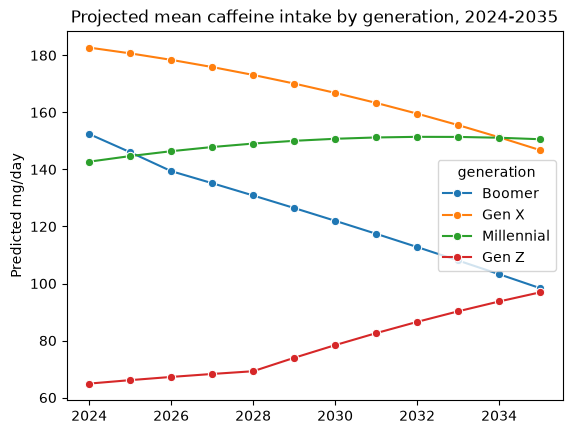

In [7]:
GENERATIONS = [("Silent", 1928, 1945), ("Boomer", 1946, 1964), ("Gen X", 1965, 1980),
               ("Millennial", 1981, 1996), ("Gen Z", 1997, 2012)]

def assign_generation(by):
    return next((n for n, s, e in GENERATIONS if s <= by <= e), "Other")

FEATS = ["age", "age2", "birth_year"]

# Final model uses every cycle, including the holdout.
final = LinearRegression().fit(
    df.assign(age2=lambda d: d.age ** 2)[FEATS], df[TARGET], sample_weight=df.diet_weight)

grid = (pd.DataFrame([(y, b) for y in range(2024, 2036) for b in range(1946, 2011)],
                     columns=["year", "birth_year"])
          .assign(age=lambda d: d.year - d.birth_year)
          .query("18 <= age <= 80")
          .assign(age2=lambda d: d.age ** 2,
                  generation=lambda d: d.birth_year.map(assign_generation)))

# Clip at zero: negative caffeine is not a thing.
grid["pred_mg"] = final.predict(grid[FEATS]).clip(0)

proj = (grid.query("generation != 'Other'")
            .groupby(["year", "generation"], as_index=False)
            .agg(pred_mg=("pred_mg", "mean"), cohorts=("birth_year", "size")))

ax = sns.lineplot(data=proj, x="year", y="pred_mg", hue="generation",
                  hue_order=[g for g in GEN_ORDER if g in set(proj.generation)], marker="o")
ax.set(title="Projected mean caffeine intake by generation, 2024-2035",
       xlabel="", ylabel="Predicted mg/day");

In [8]:
# Like-for-like comparison: predicted intake at a fixed age across cohorts
at35 = pd.DataFrame({"birth_year": range(1960, 2001)}).assign(age=35, age2=35**2)
at35["pred_mg"] = final.predict(at35[FEATS]).clip(0)
at35["generation"] = at35.birth_year.map(assign_generation)

print("Predicted intake at age 35, by cohort:")
print(at35.groupby("generation").pred_mg.mean().round(0).to_string(), "\n")

# Category level: mean across all adults 18-80 in each year
overall = grid.groupby("year", as_index=False).pred_mg.mean()
first, last = overall.pred_mg.iloc[0], overall.pred_mg.iloc[-1]
print(f"All-adult mean: {first:.0f} mg (2024) -> {last:.0f} mg (2035), "
      f"{100 * (last / first - 1):+.1f}%")

Predicted intake at age 35, by cohort:
generation
Boomer        208.0
Gen X         183.0
Gen Z         120.0
Millennial    144.0 

All-adult mean: 143 mg (2024) -> 127 mg (2035), -11.7%


Holdout MAE on cohort share above 400mg: 4.0 percentage points



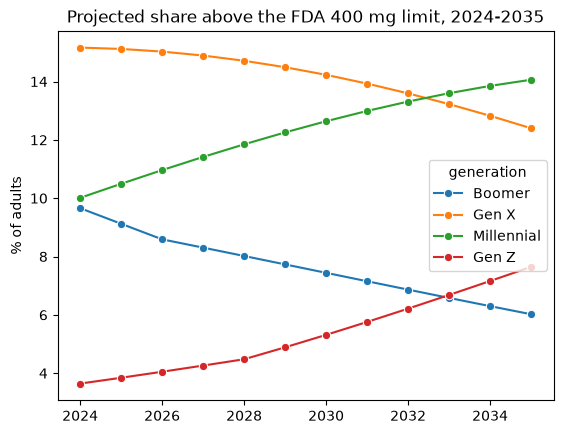

In [9]:
from sklearn.linear_model import LogisticRegression

d = df.assign(age2=lambda x: x.age ** 2,
              over=lambda x: (x.caffeine_mg > 400).astype(int))
tr = d.query("cycle_start <= @TRAIN_MAX")
te = d.query("cycle_start >  @TRAIN_MAX")

# Validate on the same holdout before trusting it.
clf = LogisticRegression(max_iter=1000).fit(tr[FEATS], tr.over, sample_weight=tr.diet_weight)
te = te.assign(p=clf.predict_proba(te[FEATS])[:, 1])

chk = (te.assign(age_band=lambda x: x.age // 10 * 10,
                 w_act=lambda x: x.over * x.diet_weight,
                 w_pred=lambda x: x.p * x.diet_weight)
         .groupby(["cycle", "generation", "age_band"], as_index=False)
         .agg(w_act=("w_act", "sum"), w_pred=("w_pred", "sum"),
              w=("diet_weight", "sum"), n=("over", "size"))
         .query("n >= 50"))
mae_pp = (100 * chk.w_pred / chk.w - 100 * chk.w_act / chk.w).abs().mean()
print(f"Holdout MAE on cohort share above 400mg: {mae_pp:.1f} percentage points\n")

# Refit on everything, project forward.
clf_final = LogisticRegression(max_iter=1000).fit(d[FEATS], d.over, sample_weight=d.diet_weight)
grid["pct_over_400"] = 100 * clf_final.predict_proba(grid[FEATS])[:, 1]

risk_proj = grid.groupby(["year", "generation"], as_index=False).pct_over_400.mean()

ax = sns.lineplot(data=risk_proj, x="year", y="pct_over_400", hue="generation",
                  hue_order=[g for g in GEN_ORDER if g in set(risk_proj.generation)], marker="o")
ax.set(title="Projected share above the FDA 400 mg limit, 2024-2035",
       xlabel="", ylabel="% of adults");

In [10]:
actual_mean = (100 * chk.w_act / chk.w).mean()
print(f"mean actual share in holdout: {actual_mean:.1f}%")
print(f"relative error: {100 * mae_pp / actual_mean:.0f}%")

mean actual share in holdout: 6.2%
relative error: 64%


### Threshold model: built, validated, rejected

A weighted logistic regression on the same features was fitted to predict the
share of each cohort exceeding the FDA 400 mg limit.

It failed validation. Holdout MAE was 4.0 percentage points against a mean
actual share of 6.2%, a relative error of 64%, compared with 11.6% for the
intake model.

It also contradicted observed behaviour: notebook 03 shows Millennials flat
near 5% for two decades with no rise as they aged, while the model projects
them climbing to 14%. The pooled age curve is overriding the cohort's actual
trajectory.

**Why it fails where the intake model succeeds:** means move smoothly, but
threshold exceedance is driven by the tail of the distribution, and tail
behaviour differs across cohorts in ways that age + age² + birth year cannot
capture.

**Decision: no threshold forecast is published.** The dashboard reports
observed historical shares only. Projecting this would imply a confidence the
validation does not support.

In [11]:
FORECAST = Path("../data/clean")

proj.round(1).to_csv(FORECAST / "forecast_intake_by_generation.csv", index=False)
at35[["birth_year", "generation", "pred_mg"]].round(1).to_csv(
    FORECAST / "forecast_intake_at_age35.csv", index=False)
overall.round(1).to_csv(FORECAST / "forecast_all_adults.csv", index=False)
a2[["cycle", "generation", "age_band", "n", "actual", "predicted", "error"]].round(1).to_csv(
    FORECAST / "model_holdout_validation.csv", index=False)

for f in ["forecast_intake_by_generation", "forecast_intake_at_age35",
          "forecast_all_adults", "model_holdout_validation"]:
    print(f"{f}.csv")

forecast_intake_by_generation.csv
forecast_intake_at_age35.csv
forecast_all_adults.csv
model_holdout_validation.csv
